دانشجو: هدی
میزان ساعت مطالعه: 4.0 ساعت
نتیجه پیش‌بینی مدل: قبولی در آزمون
دقت کلی مدل: 66.7%


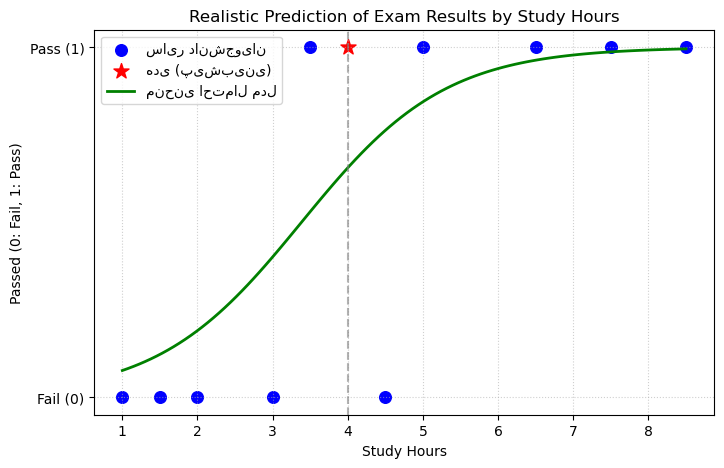

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


data = {
    'Student_Name': ['Ali', 'Sara', 'Reza', 'Neda', 'Mina', 'Omid', 'Taha', 'Hassan', 'Zahra', 'Babak'],
    'Study_Hours': [1.0, 1.5, 2.0, 3.0, 3.5, 4.5, 5.0, 6.5, 7.5, 8.5],
    'Passed': [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]  # کمی تداخل طبیعی برای واقع‌گرایی مدل
}

df = pd.DataFrame(data)

X = df[['Study_Hours']]
y = df['Passed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

hoda_hours = 4.0
hoda_input = pd.DataFrame({'Study_Hours': [hoda_hours]})
hoda_result = model.predict(hoda_input)[0]

print("=" * 45)
print(f"دانشجو: هدی")
print(f"میزان ساعت مطالعه: {hoda_hours} ساعت")

if hoda_result == 1:
    print("نتیجه پیش‌بینی مدل: قبولی در آزمون")
else:
    print("نتیجه پیش‌بینی مدل: عدم قبولی در آزمون")

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"دقت کلی مدل: {accuracy * 100:.1f}%")
print("=" * 45)


plt.figure(figsize=(8, 5))
plt.scatter(df['Study_Hours'], df['Passed'], color='blue', s=70, label='سایر دانشجویان')
plt.scatter([hoda_hours], [hoda_result], color='red', s=130, marker='*', label='هدی (پیش‌بینی)')


X_range = np.linspace(df['Study_Hours'].min(), df['Study_Hours'].max(), 100).reshape(-1, 1)
X_range_df = pd.DataFrame(X_range, columns=['Study_Hours'])
y_prob = model.predict_proba(X_range_df)[:, 1]
plt.plot(X_range, y_prob, color='green', linestyle='-', linewidth=2, label='منحنی احتمال مدل')

plt.axvline(x=hoda_hours, color='gray', linestyle='--', alpha=0.6)
plt.title('Realistic Prediction of Exam Results by Study Hours')
plt.xlabel('Study Hours')
plt.ylabel('Passed (0: Fail, 1: Pass)')
plt.yticks([0, 1], ['Fail (0)', 'Pass (1)'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
